<a href="https://colab.research.google.com/github/Priyankaewp/schools-project/blob/main/DataCleaningDay3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("titanic.csv.xlsx")
print(df.shape)

(891, 15)


In [3]:
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [12]:
# Text Cleaning
df['embark_town'] = (df["embark_town"]
                     .astype("string")
                     .str.strip()
                     .str.title())

In [13]:
# deck
df['deck'] = (df["deck"]
              .astype("string")
              .str.strip()
              .str.upper())
print(df[["embark_town", "deck"]].head(10))

   embark_town  deck
0  Southampton  <NA>
1    Cherbourg     C
2  Southampton  <NA>
3  Southampton     C
4  Southampton  <NA>
5   Queenstown  <NA>
6  Southampton     E
7  Southampton  <NA>
8  Southampton  <NA>
9    Cherbourg  <NA>


In [6]:
# Datatypes
print(df.dtypes)

survived                int64
pclass                  int64
sex                    object
age                   float64
sibsp                   int64
parch                   int64
fare                  float64
embarked               object
class                  object
who                    object
adult_male               bool
deck           string[python]
embark_town            object
alive                  object
alone                    bool
embard_town    string[python]
dtype: object


In [9]:
df["age"] = pd.to_numeric(df["age"], errors = "coerce")
df["fare"] = pd.to_numeric(df["fare"], errors = "coerce")

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: age, dtype: float64


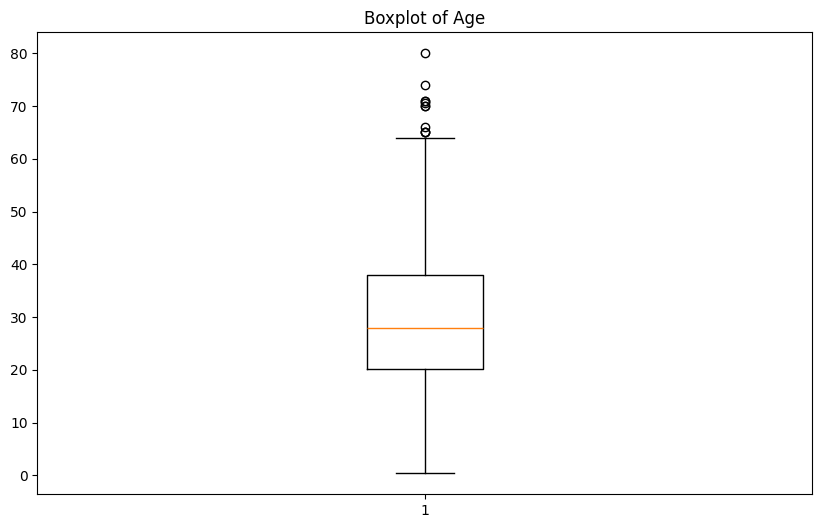

In [11]:
# Outliers - age
print(df['age'].describe())
plt.figure(figsize = (10,6))
plt.boxplot(df['age'].dropna())
plt.title("Boxplot of Age")
plt.show()

In [15]:
# IQR - age
Q1 =df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

17.875


In [17]:
lower = Q1 - 1.5*IQR
upper = Q3+ 1.5*IQR
print(lower)
print(upper)

-6.6875
64.8125


In [18]:
# display outliers - age
outliers = df[(df['age']<lower) | (df['age']>upper)]
print(outliers)

     survived  pclass   sex   age  sibsp  parch     fare embarked   class  \
33          0       2  male  66.0      0      0  10.5000        S  Second   
54          0       1  male  65.0      0      1  61.9792        C   First   
96          0       1  male  71.0      0      0  34.6542        C   First   
116         0       3  male  70.5      0      0   7.7500        Q   Third   
280         0       3  male  65.0      0      0   7.7500        Q   Third   
456         0       1  male  65.0      0      0  26.5500        S   First   
493         0       1  male  71.0      0      0  49.5042        C   First   
630         1       1  male  80.0      0      0  30.0000        S   First   
672         0       2  male  70.0      0      0  10.5000        S  Second   
745         0       1  male  70.0      1      1  71.0000        S   First   
851         0       3  male  74.0      0      0   7.7750        S   Third   

     who  adult_male  deck  embark_town alive  alone  embard_town  
33   ma

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: fare, dtype: float64


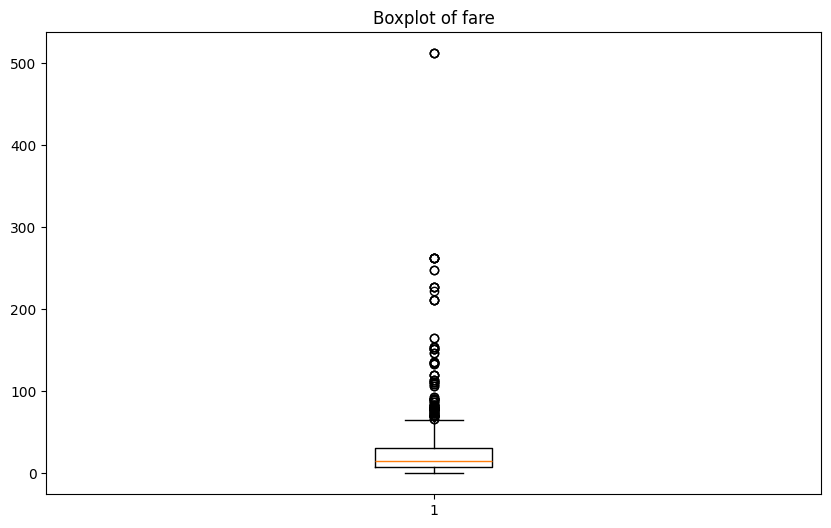

In [19]:
# Outliers - fare
print(df['fare'].describe())
plt.figure(figsize = (10,6))
plt.boxplot(df['fare'].dropna())
plt.title("Boxplot of fare")
plt.show()

In [20]:
# IQR - Fare
Q1 =df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1
print(IQR)

23.0896


In [21]:
lower = Q1 - 1.5*IQR
upper = Q3+ 1.5*IQR
print(lower)
print(upper)

-26.724
65.6344


In [22]:
# display outliers - fare
outliers = df[(df['fare']<lower) | (df['fare']>upper)]
print(outliers)

     survived  pclass     sex   age  sibsp  parch      fare embarked  class  \
1           1       1  female  38.0      1      0   71.2833        C  First   
27          0       1    male  19.0      3      2  263.0000        S  First   
31          1       1  female   NaN      1      0  146.5208        C  First   
34          0       1    male  28.0      1      0   82.1708        C  First   
52          1       1  female  49.0      1      0   76.7292        C  First   
..        ...     ...     ...   ...    ...    ...       ...      ...    ...   
846         0       3    male   NaN      8      2   69.5500        S  Third   
849         1       1  female   NaN      1      0   89.1042        C  First   
856         1       1  female  45.0      1      1  164.8667        S  First   
863         0       3  female   NaN      8      2   69.5500        S  Third   
879         1       1  female  56.0      0      1   83.1583        C  First   

       who  adult_male  deck  embark_town alive  al

In [26]:
from google.colab import files
df.to_csv("titanic_cleanedfile.csv", index= False)
files.download("titanic_cleanedfile.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>